# Notebook 04 — Feature Engineering & Class Balancing
**Project:** Predicting Employee Attrition at PeopleFirst Global Services
**Step:** Month 2, Week 8 — Create new features, handle class imbalance with SMOTE

---
### Objectives of this notebook
1. Create new engineered features based on EDA findings
2. Handle class imbalance using SMOTE (on training split only)
3. Perform train/test split (stratified, time-based if timestamp available)
4. Save final train and test sets for model development

> **Input:** `data/processed/PeopleFirst_cleaned.csv`
> **Output:** `data/processed/X_train.csv`, `X_test.csv`, `y_train.csv`, `y_test.csv`


## 1. Import Libraries & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import warnings, os

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')

os.makedirs('../data/processed', exist_ok=True)
os.makedirs('../reports', exist_ok=True)

df = pd.read_csv('../data/processed/PeopleFirst_cleaned.csv')
print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Class distribution:")
print(df['attrition_flag'].value_counts())
print(f"Attrition rate: {df['attrition_flag'].mean()*100:.1f}%")


Dataset loaded: 50,500 rows x 31 columns
Class distribution:
attrition_flag
1    31029
0    19471
Name: count, dtype: int64
Attrition rate: 61.4%


## 2. Feature Engineering
Based on EDA findings, we create 5 new features that capture non-linear patterns
the model cannot easily learn from raw columns alone.


### 2a. Engagement Composite Score
**What:** Multiply engagement_score x work_life_balance_score

**Why:** Both individually correlate with attrition, but an employee who scores
LOW on BOTH is at much higher risk than someone who scores low on just one.
Multiplying creates an interaction term that captures this compound effect.
A LightGBM tree can find this pattern itself, but giving it directly as a feature
speeds up learning and makes it more explicit in SHAP.


In [2]:
df['engagement_wlb_composite'] = df['engagement_score'] * df['work_life_balance_score']
print("engagement_wlb_composite created.")
print(f"  Range: {df['engagement_wlb_composite'].min():.3f} to {df['engagement_wlb_composite'].max():.3f}")
print(f"  Correlation with attrition: {df['engagement_wlb_composite'].corr(df['attrition_flag']):.3f}")


engagement_wlb_composite created.
  Range: -3.168 to 3.133
  Correlation with attrition: -0.038


### 2b. Tenure Bucket
**What:** Bin years_at_company into 3 categories: Early (<2y), Mid (2-5y), Senior (5y+)

**Why:** The relationship between tenure and attrition is NOT linear — it's U-shaped.
New employees leave (exploring), mid-tenure employees are most stable, and senior employees
may leave again if career growth stalls. A single numeric value can't capture this shape
— a categorical bucket can.

> Note: years_at_company is Z-score scaled in our cleaned dataset.
> We reconstruct approximate buckets using quantile thresholds.


In [3]:

q33 = df['years_at_company'].quantile(0.33)
q66 = df['years_at_company'].quantile(0.66)

df['tenure_bucket'] = pd.cut(
    df['years_at_company'],
    bins=[-np.inf, q33, q66, np.inf],
    labels=[0, 1, 2]   # 0=Early, 1=Mid, 2=Senior
).astype(int)

print("tenure_bucket created (0=Early, 1=Mid, 2=Senior):")
print(df['tenure_bucket'].value_counts().sort_index())
print()
print("Attrition rate by tenure bucket:")
print(df.groupby('tenure_bucket')['attrition_flag'].mean().round(3))


tenure_bucket created (0=Early, 1=Mid, 2=Senior):
tenure_bucket
0    17709
1    17767
2    15024
Name: count, dtype: int64

Attrition rate by tenure bucket:
tenure_bucket
0    0.608
1    0.620
2    0.615
Name: attrition_flag, dtype: float64


### 2c. Below-Department-Median Salary Flag
**What:** 1 if employee's salary is below their department's median salary, else 0

**Why:** Absolute salary alone is less informative than relative salary.
An employee earning 50K may feel fairly paid in a low-salary department,
but underpaid in a high-salary one. This flag captures *relative underpayment*
within peer groups — a much stronger attrition signal.


In [4]:
dept_median_salary = df.groupby('department')['monthly_salary'].transform('median')
df['below_dept_median_salary'] = (df['monthly_salary'] < dept_median_salary).astype(int)

pct_below = df['below_dept_median_salary'].mean() * 100
print(f"below_dept_median_salary created.")
print(f"  {pct_below:.1f}% of employees are paid below their department median")
print()
print("Attrition rate by below-median flag:")
print(df.groupby('below_dept_median_salary')['attrition_flag'].mean().round(3))


below_dept_median_salary created.
  50.0% of employees are paid below their department median

Attrition rate by below-median flag:
below_dept_median_salary
0    0.614
1    0.615
Name: attrition_flag, dtype: float64


### 2d. Satisfaction Composite Score
**What:** Average of the 3 satisfaction-related scores:
employee_satisfaction_score, manager_relationship_score, work_life_balance_score

**Why:** These three scores measure related but distinct dimensions of employee
wellbeing. An average gives a single summary score — employees with a low
composite are at risk across ALL satisfaction dimensions simultaneously,
which is a stronger signal than any single score.


In [5]:
df['satisfaction_composite'] = (
    df['employee_satisfaction_score'] +
    df['manager_relationship_score'] +
    df['work_life_balance_score']
) / 3

print("satisfaction_composite created.")
print(f"  Correlation with attrition: {df['satisfaction_composite'].corr(df['attrition_flag']):.3f}")
print(f"  Mean for Stayed: {df[df['attrition_flag']==0]['satisfaction_composite'].mean():.3f}")
print(f"  Mean for Left:   {df[df['attrition_flag']==1]['satisfaction_composite'].mean():.3f}")


satisfaction_composite created.
  Correlation with attrition: -0.460
  Mean for Stayed: 0.335
  Mean for Left:   -0.210


### 2e. Burnout Risk Index
**What:** Combine overtime hours and absenteeism into a single burnout proxy

**Why:** High overtime drives initial burnout. When burnout sets in, absenteeism
increases as the employee starts disengaging before eventually leaving.
Multiplying the two amplifies the signal for employees who show BOTH signs —
high overtime AND high absenteeism — the highest-risk burnout pattern.


In [6]:
df['burnout_index'] = df['avg_monthly_overtime_hours'] * (1 + df['absenteeism_days_last_12m'])

print("burnout_index created.")
print(f"  Correlation with attrition: {df['burnout_index'].corr(df['attrition_flag']):.3f}")
print()
print("New engineered features summary:")
new_features = ['engagement_wlb_composite', 'tenure_bucket',
                'below_dept_median_salary', 'satisfaction_composite', 'burnout_index']
for f in new_features:
    corr = df[f].corr(df['attrition_flag'])
    print(f"  {f:35s}  corr={corr:+.3f}")


burnout_index created.
  Correlation with attrition: 0.060

New engineered features summary:
  engagement_wlb_composite             corr=-0.038
  tenure_bucket                        corr=+0.006
  below_dept_median_salary             corr=+0.001
  satisfaction_composite               corr=-0.460
  burnout_index                        corr=+0.060


In [7]:
print(f"\nFinal dataset shape after feature engineering: {df.shape}")
print(f"Columns now: {df.shape[1]} (was 31, added 5 new features)")



Final dataset shape after feature engineering: (50500, 36)
Columns now: 36 (was 31, added 5 new features)


## 3. Train / Test Split

**Strategy: Stratified random split (70/30)**

Rationale:
- The dataset does not have an explicit timestamp column available for time-based split.
- We use stratified sampling to preserve the 61.4% / 38.6% class ratio in both train and test sets.
- Test set is held out completely and NEVER touched during SMOTE or model training.
- This prevents data leakage — the model never sees test data during training.

> If a hire_date or join_date column becomes available in a future data version,
> switch to time-based split: sort by date, use first 80% for training, last 20% for testing.


In [8]:
TARGET = 'attrition_flag'
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y  
)

print(f"Train set: {X_train.shape[0]:,} rows ({X_train.shape[0]/len(df)*100:.0f}%)")
print(f"Test set:  {X_test.shape[0]:,} rows  ({X_test.shape[0]/len(df)*100:.0f}%)")
print()
print("Class distribution in train:")
print(y_train.value_counts())
print(f"Train attrition rate: {y_train.mean()*100:.1f}%")
print()
print("Class distribution in test:")
print(y_test.value_counts())
print(f"Test attrition rate: {y_test.mean()*100:.1f}%")
print()
print("Stratification confirmed: train and test have the same ratio.")


Train set: 35,350 rows (70%)
Test set:  15,150 rows  (30%)

Class distribution in train:
attrition_flag
1    21720
0    13630
Name: count, dtype: int64
Train attrition rate: 61.4%

Class distribution in test:
attrition_flag
1    9309
0    5841
Name: count, dtype: int64
Test attrition rate: 61.4%

Stratification confirmed: train and test have the same ratio.


## 4. Handle Class Imbalance — SMOTE

**The Problem:**
Our dataset has 61.4% Left (majority) vs 38.6% Stayed (minority).
A naive model could achieve 61.4% accuracy by predicting "Left" for everyone.
More importantly, the model would fail to predict "Stayed" correctly —
and HR cares about correctly identifying the employees who WILL stay (false negatives
in the other direction cost retention budget unnecessarily).

**SMOTE (Synthetic Minority Over-sampling Technique):**
- Creates *synthetic* (not duplicated) examples of the minority class
- Works by interpolating between existing minority class examples in feature space
- Applied ONLY to the training set — test set is NEVER touched
- After SMOTE, training set becomes 50/50 balanced

**Why not just duplicate (random over-sample)?**
Duplication creates exact copies — the model memorizes those rows.
SMOTE creates new, slightly different examples by interpolating between
nearest neighbors, giving the model more *variety* to generalize from.

**Why not under-sample the majority?**
Under-sampling throws away real data. With 50,500 rows we can afford over-sampling.


In [9]:
print("Before SMOTE:")
print(f"  Train set: {len(y_train):,} rows")
print(f"  Class 0 (Stayed): {(y_train==0).sum():,} ({(y_train==0).mean()*100:.1f}%)")
print(f"  Class 1 (Left):   {(y_train==1).sum():,} ({(y_train==1).mean()*100:.1f}%)")

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("\nAfter SMOTE:")
print(f"  Train set: {len(y_train_bal):,} rows")
print(f"  Class 0 (Stayed): {(y_train_bal==0).sum():,} ({(y_train_bal==0).mean()*100:.1f}%)")
print(f"  Class 1 (Left):   {(y_train_bal==1).sum():,} ({(y_train_bal==1).mean()*100:.1f}%)")
print()
print("Test set is UNCHANGED (never touched by SMOTE):")
print(f"  Test:  {len(y_test):,} rows | {(y_test==0).mean()*100:.1f}% Stayed | {(y_test==1).mean()*100:.1f}% Left")


Before SMOTE:
  Train set: 35,350 rows
  Class 0 (Stayed): 13,630 (38.6%)
  Class 1 (Left):   21,720 (61.4%)

After SMOTE:
  Train set: 43,440 rows
  Class 0 (Stayed): 21,720 (50.0%)
  Class 1 (Left):   21,720 (50.0%)

Test set is UNCHANGED (never touched by SMOTE):
  Test:  15,150 rows | 38.6% Stayed | 61.4% Left


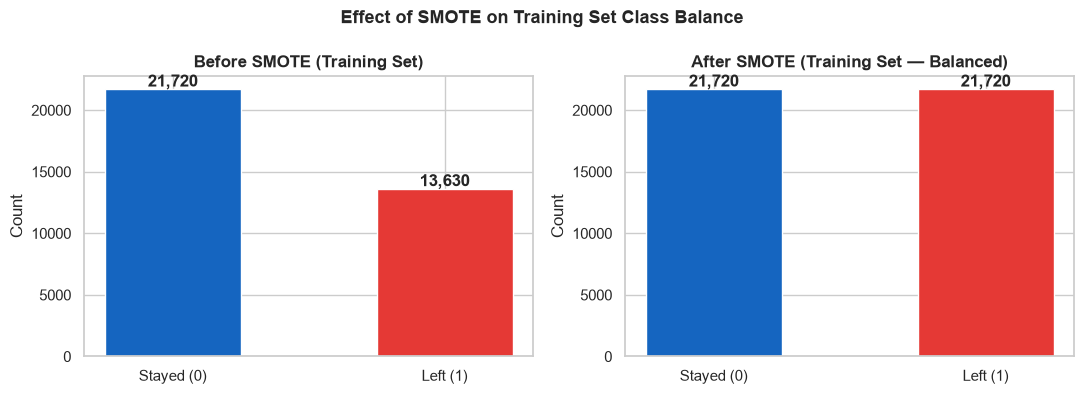

In [10]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4))


before_counts = y_train.value_counts()
axes[0].bar(['Stayed (0)', 'Left (1)'], before_counts.values,
            color=['#1565C0', '#E53935'], edgecolor='white', width=0.5)
for i, v in enumerate(before_counts.values):
    axes[0].text(i, v + 200, f'{v:,}', ha='center', fontweight='bold')
axes[0].set_title('Before SMOTE (Training Set)', fontweight='bold')
axes[0].set_ylabel('Count')


after_counts = pd.Series(y_train_bal).value_counts()
axes[1].bar(['Stayed (0)', 'Left (1)'], after_counts.values,
            color=['#1565C0', '#E53935'], edgecolor='white', width=0.5)
for i, v in enumerate(after_counts.values):
    axes[1].text(i, v + 200, f'{v:,}', ha='center', fontweight='bold')
axes[1].set_title('After SMOTE (Training Set — Balanced)', fontweight='bold')
axes[1].set_ylabel('Count')

plt.suptitle('Effect of SMOTE on Training Set Class Balance', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/04_smote_balance.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Feature Correlation Check — Final Feature Set
Quick check: correlation of all final features (including engineered ones) with target,
to confirm the new features add value.


Top 20 features by correlation with attrition_flag:
satisfaction_composite         0.460
manager_relationship_score     0.267
employee_satisfaction_score    0.267
work_life_balance_score        0.261
engagement_score               0.256
promotion_last_5y              0.201
years_in_current_role          0.172
salary_hike_pct                0.108
avg_monthly_overtime_hours     0.087
burnout_index                  0.061
engagement_wlb_composite       0.040
absenteeism_days_last_12m      0.013
years_at_company               0.011
tenure_bucket                  0.011
employment_type                0.011
performance_rating             0.010
job_role                       0.006
late_arrivals_last_12m         0.005
certifications_completed       0.005
recruitment_source             0.004


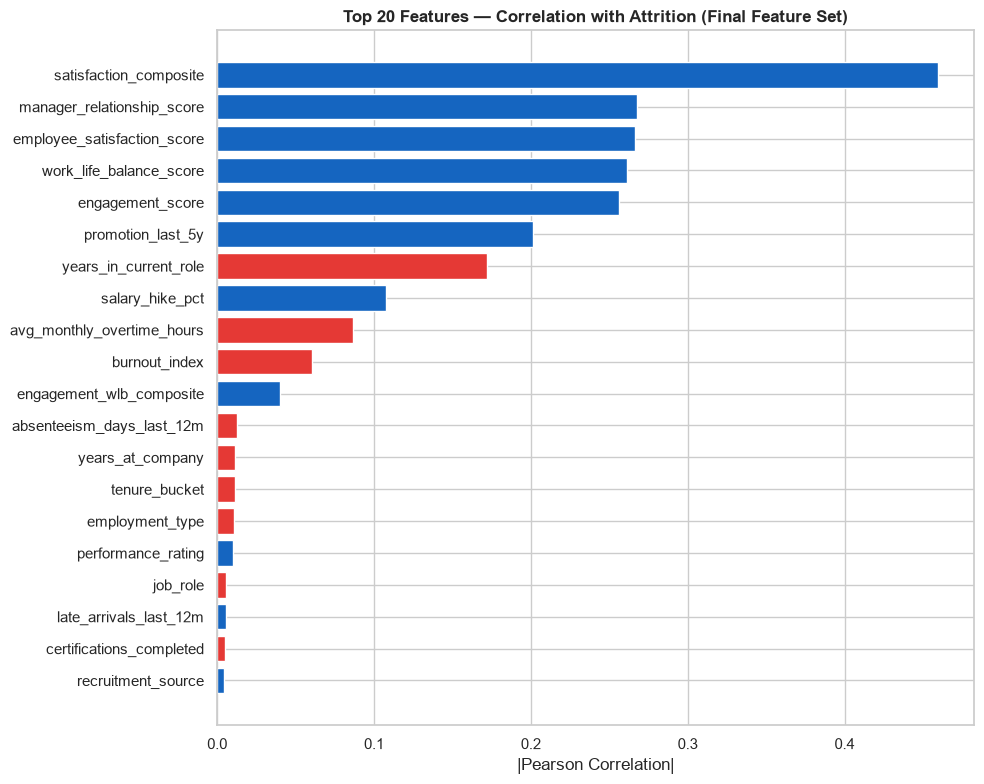

In [11]:

combined = X_train.copy()
combined['attrition_flag'] = y_train.values

final_corr = combined.corr()['attrition_flag'].drop('attrition_flag').abs().sort_values(ascending=False)

print("Top 20 features by correlation with attrition_flag:")
print(final_corr.head(20).round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 8))
top20 = final_corr.head(20)
raw_corr = combined.corr()['attrition_flag'].drop('attrition_flag')
colors = ['#E53935' if raw_corr[col] > 0 else '#1565C0' for col in top20.index]
ax.barh(top20.index[::-1], top20.values[::-1], color=colors[::-1], edgecolor='white')
ax.set_title('Top 20 Features — Correlation with Attrition (Final Feature Set)',
             fontweight='bold')
ax.set_xlabel('|Pearson Correlation|')
plt.tight_layout()
plt.savefig('../reports/04_final_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Save Train / Test Sets

In [12]:

X_train_bal_df = pd.DataFrame(X_train_bal, columns=X_train.columns)
y_train_bal_df = pd.Series(y_train_bal, name='attrition_flag')

X_train_bal_df.to_csv('../data/processed/X_train.csv', index=False)
X_test.to_csv('../data/processed/X_test.csv', index=False)
y_train_bal_df.to_csv('../data/processed/y_train.csv', index=False)
y_test.to_csv('../data/processed/y_test.csv', index=False)

print("Saved:")
print(f"  X_train.csv : {X_train_bal_df.shape[0]:,} rows x {X_train_bal_df.shape[1]} cols (SMOTE balanced)")
print(f"  X_test.csv  : {X_test.shape[0]:,} rows x {X_test.shape[1]} cols (original)")
print(f"  y_train.csv : {len(y_train_bal_df):,} labels (SMOTE balanced)")
print(f"  y_test.csv  : {len(y_test):,} labels (original)")
print()
print("=== Notebook 04 Complete ===")
print("Proceed to: notebooks/05_model_development.ipynb")


Saved:
  X_train.csv : 43,440 rows x 35 cols (SMOTE balanced)
  X_test.csv  : 15,150 rows x 35 cols (original)
  y_train.csv : 43,440 labels (SMOTE balanced)
  y_test.csv  : 15,150 labels (original)

=== Notebook 04 Complete ===
Proceed to: notebooks/05_model_development.ipynb
